# Probability and Statistics Lab 2: random variables, and limit theorems

## General comments and instructions

-   The report must be prepared as *jupyter notebook along with compiled PDF*.
-   For each task, include
    -   the statistics obtained (like sample mean or anything else you use to complete the task) as well as histograms etc to illustrate your findings;
    -   justification of your solution (e.g. refer to the corresponding theorems from probability theory); whenever applicable, provide LaTeX formulas and derivations.
    -   conclusions (e.g. how reliable your answer is, does it agree with common sense expectations etc.).
-   Not complying with these instructions may result in point deduction.


### Work breakdown:

- Anna Kravchenko - Taks 1
- Veronika Parkhomenko - Task 2
- Parvlo Krailo - Task 3, 4


A **team id number** referred to in tasks is the **two-digit** ordinal number of your team on the list. We keep it for reproducible calculations.

In [35]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import ecdf, norm, poisson, binom, gamma

team_id: int = 33

random.seed(team_id)
np.random.seed(team_id)

z975 = norm.ppf(0.975)
z95 = norm.ppf(0.95)

## Task 1. Hamming codes


In this task, we discuss the $[7, 4]$ Hamming code and investigate its reliability. That coding system can correct single errors in the transmission of 4-bit messages and proceeds as follows:

(a) given a message $m = (a_1a_2a_3a_4)$, we first encode it to a 7-bit codeword $c = mG = (x_1x_2x_3x_4x_5x_6x_7)$, where $G$ is a $4 \times 7$ generator matrix

(b) the codeword $c$ is transmitted, and $r$ is the received message

(c) $r$ is checked for errors by calculating the syndrome vector $z := rH$, for a $7 \times 3$ parity-check matrix $H$

(d) if a single error has occurred in $r$, then the binary $z = (z_1z_2z_3)$ identifies the wrong bit no. $z_1 + 2z_2 + 4z_3$; thus $(000)$ shows there was no error (or more than one), while $(110)$ means the third bit (or more than one) got corrupted

(e) if the error was identified, then we flip the corresponding bit in $r$ to get the corrected $r^* = (r_1^*r_2^*r_3^*r_4^*r_5^*r_6^*r_7^*)$; the decoded message is then $m^* := (r_3^*r_5^*r_6^*r_7^*)$.

The generator matrix $G$ and the parity-check matrix $H$ are given by

$$
G := \begin{pmatrix}
1 & 1 & 1 & 0 & 0 & 0 & 0 \\
1 & 0 & 0 & 1 & 1 & 0 & 0 \\
0 & 1 & 0 & 1 & 0 & 1 & 0 \\
1 & 1 & 0 & 1 & 0 & 0 & 1
\end{pmatrix},
\qquad
H^\top := \begin{pmatrix}
1 & 0 & 1 & 0 & 1 & 0 & 1 \\
0 & 1 & 1 & 0 & 0 & 1 & 1 \\
0 & 0 & 0 & 1 & 1 & 1 & 1
\end{pmatrix}
$$
*$GH$ must equal a zero-matrix modulo 2.*


Assume that each bit in the transmission $c \mapsto r$ gets corrupted independently of the others with probability $p = (2 + \frac{\text{team-id-number}}{4})/100$. Your task:

1. Simulate the encoding-transmission-decoding process $N$ times and find the estimate $\hat p$ of the probability $p^*$ of correct transmission of a single message $m$. Comment why, for large $N$, $\hat p$ is expected to be close to $p^*$.
2. By estimating the standard deviation of the corresponding indicator of success by the sample standard deviation and using the CLT, find the half-length $\varepsilon$ of the confidence interval $(\hat p - \varepsilon, \hat p + \varepsilon)$, which contains the true value $p^*$ with probability at least $0.95$. What choice of $N$ guarantees that $\varepsilon \le 0.03$?
3. Draw the histogram of the number $k = 0, 1, 2, 3, 4$ of errors in $m^*$ while transmitting a 4-digit binary message. Do you think the random variable that counts the number of wrong bits in a decoded message has one of the known distributions? Justify your answer.


#### Task 1.1: simulation and the law of large numbers

In [36]:
G = np.array([[1, 1, 1, 0, 0, 0, 0],
              [1, 0, 0, 1, 1, 0, 0],
              [0, 1, 0, 1, 0, 1, 0],
              [1, 1, 0, 1, 0, 0, 1]])
H = np.array([[1, 0, 1, 0, 1, 0, 1],
              [0, 1, 1, 0, 0, 1, 1],
              [0, 0, 0, 1, 1, 1, 1]]).T
print("G H mod 2 =\n", (G @ H) % 2)

p = (2 + team_id / 4) / 100
N = 100_000

m = np.random.randint(0, 2, size=(N, 4))
c = (m @ G) % 2
r = (c + (np.random.rand(N, 7) < p)) % 2
z = (r @ H) % 2
pos = z @ [1, 2, 4]
bad = pos > 0
r[np.where(bad)[0], pos[bad] - 1] ^= 1
m_star = r[:, [2, 4, 5, 6]]

success = np.all(m == m_star, axis=1)
p_hat = success.mean()
p_exact = (1 - p)**7 + 7 * p * (1 - p)**6
print(f"p = {p}")
print(f"N = {N}")
print(f"p_hat = {p_hat:.4f}")
print(f"exact p* = {p_exact:.4f}")

G H mod 2 =
 [[0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]]
p = 0.1025
N = 100000
p_hat = 0.8441
exact p* = 0.8441


**Setup.** For team 33, $p = (2 + 33/4)/100 = 0.1025$. The check $GH = 0 \pmod 2$ gives the zero matrix, so $G$ and $H$ are consistent.

**Result.** Over $N = 100\,000$ simulated messages, the fraction transmitted correctly is
$$\hat p = 0.8441 .$$

**Exact value.** The Hamming code corrects one flipped bit but never fixes two or more (it is a *perfect* code, so with two or more flips the decoder always lands on a wrong codeword). So a message is correct exactly when at most one of the 7 bits is flipped:
$$p^* = (1-p)^7 + 7p(1-p)^6 = 0.8441 .$$

**Why $\hat p \approx p^*$.** Each message succeeds independently with probability $p^*$, so $\hat p$ is an average of i.i.d. Bernoulli$(p^*)$ variables. By the law of large numbers it converges to $p^*$ as $N$ grows.

**Conclusion.** $\hat p$ and $p^*$ agree to four decimals: about 84% of messages arrive correctly.

#### Task 1.2: confidence interval and the choice of $N$

In [37]:
s = success.std(ddof=1)
eps = z975 * s / np.sqrt(N)
print(f"s = {s:.4f}, eps = {eps:.5f}, 95% CI = ({p_hat - eps:.4f}, {p_hat + eps:.4f})")

print("N for our s:", int(np.ceil((z975 * s / 0.03)**2)))
print("N for any s (s <= 0.5):", int(np.ceil((z975 * 0.5 / 0.03)**2)))

s = 0.3628, eps = 0.00225, 95% CI = (0.8418, 0.8463)
N for our s: 562
N for any s (s <= 0.5): 1068


**Theory.** $\hat p$ is the mean of $N$ i.i.d. Bernoulli$(p^*)$ variables, so by the CLT it is approximately normal around $p^*$. Using the sample standard deviation $s$ in place of the true one, the half-length of the 95% confidence interval is
$$\varepsilon = 1.96\,\frac{s}{\sqrt N}.$$

**Numbers.** $s = 0.3628$ and $\varepsilon = 0.00225$, so the interval is $(0.8418,\ 0.8463)$. It contains $p^* = 0.8441$.

**Choice of $N$.** $\varepsilon \le 0.03$ means $N \ge (1.96\,s/0.03)^2$. For our $s \approx 0.363$ this gives $N \ge 562$. Since $s \le \tfrac12$ for any probability, $N = 1068$ works in every case.

**Conclusion.** With $N = 10^5$ the error is only about $0.2\%$, and about a thousand messages already give $\pm 0.03$.

#### Task 1.3: number of wrong bits in the decoded message

k | simulated | Binomial(4, q)
0 | 0.84408   | 0.74986
1 | 0.06214   | 0.22382
2 | 0.06574   | 0.02505
3 | 0.02802   | 0.00125
4 | 0.00002   | 0.00002

q = 0.0694:  P(bit 1 and bit 2 wrong) = 0.0245  vs  q^2 = 0.0048
P(K = k | K >= 1): [0.399 0.422 0.18  0.   ]


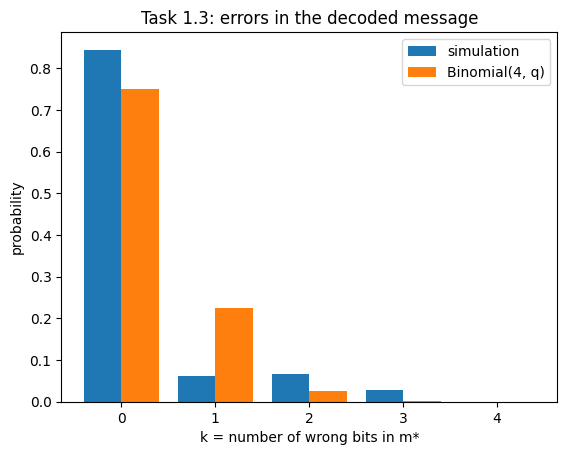

In [38]:
wrong = (m != m_star)
k = wrong.sum(axis=1)
freq = np.bincount(k, minlength=5) / N

q = wrong.mean()
binom_pmf = binom.pmf(np.arange(5), 4, q)
print("k | simulated | Binomial(4, q)")
for j in range(5):
    print(f"{j} | {freq[j]:.5f}   | {binom_pmf[j]:.5f}")

both = (wrong[:, 0] & wrong[:, 1]).mean()
print(f"\nq = {q:.4f}:  P(bit 1 and bit 2 wrong) = {both:.4f}  vs  q^2 = {q**2:.4f}")
print("P(K = k | K >= 1):", np.round(freq[1:] / freq[1:].sum(), 3))

plt.bar(np.arange(5) - 0.2, freq, width=0.4, label="simulation")
plt.bar(np.arange(5) + 0.2, binom_pmf, width=0.4, label="Binomial(4, q)")
plt.xlabel("k = number of wrong bits in m*")
plt.ylabel("probability")
plt.legend()
plt.title("Task 1.3: errors in the decoded message")
plt.show()

Let $K\in\{0,1,2,3,4\}$ be the number of wrong bits in $m^*$. If $K$ were $\mathrm{Bin}(4,q)$ with $q=0.069$ (the average chance that a decoded bit is wrong), the four decoded bits would have to be wrong independently. They are not: bits 1 and 2 are wrong together with probability $0.0245$, about five times the $q^2=0.0048$ that independence would give. The reason is that a decoding failure (probability $1-p^*=0.156$) makes the decoder output a different codeword, which differs from the sent one in at least 3 positions, so several message bits are usually damaged at once.

The histogram shows the mismatch:

| $k$ | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| simulated | 0.844 | 0.062 | 0.066 | 0.028 |
| $\mathrm{Bin}(4,q)$ | 0.750 | 0.224 | 0.025 | 0.001 |

In particular $P(K=2)>P(K=1)$, which a binomial with such a small $q$ can never give.

**Conclusion.** $K$ has no standard distribution. It is $0$ with probability $p^*=0.844$, and otherwise it is $1$, $2$ or $3$ with comparable probabilities.

## Task 2. Particle decay

In this task, we discuss a real-life process that is well modelled by a Poisson distribution. As you remember, a Poisson random variable describes occurrences of rare events, i.e., counts the number of successes in a large number of independent random experiments. One of the typical examples is the radioactive decay process.

Consider a sample of radioactive element of mass $m$, which has a large half-life period $T$; it is vitally important to know the probability that during a one second period, the number of nuclei decays will not exceed some critical level $k$. This probability can easily be estimated using the fact that, given the decay constant $\lambda$ of the element (i.e., the probability that a given nucleus decays within one second) and the number $N$ of atoms in the sample, the random number of decays within a second is well modelled by Poisson distribution with parameter $\mu := N\lambda$. Next, for the sample of mass $m$, the number of atoms is $N = \frac{m}{M} N_A$, where $N_A = 6 \times 10^{23}$ is the Avogadro constant, and $M$ is the molar (atomic) mass of the element. The decay constant, $\lambda$, is $\ln(2)/T$, where $T$ is measured in seconds.

Assume that a medical laboratory receives $n$ samples of radioactive element $^{137}\text{Cs}$ (used in radiotherapy) with half-life period $T = 30.1$ years and mass $m = (10 + \text{team-id-number}) \times 10^{-14}$ g each. Denote by $X_1, X_2, \dots, X_n$ the i.i.d. r.v.'s counting the number of decays in sample $i$ in one second.

1. Specify the parameter of the Poisson distribution of $X_i$ (you'll need the atomic mass of Cesium-137)
2. Show that the distribution of the sample means of $X_1, \dots, X_n$ gets very close to a normal one as $n$ becomes large and identify that normal distribution. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and form the empirical cumulative distribution function $\hat F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. $F$ of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $\hat F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity (use the proper scales!);
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
3. Calculate the largest possible value of $n$, for which the total number of decays in one second is less than $a := 100$ with probability more than $0.95$. To this end,
   - simulate the realization $x_1, x_2, \dots, x_n$ of the $X_i$ and calculate the sum $s = x_1 + \dots + x_n$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of sums;
   - calculate the number of elements of the sample which are less than critical value ($a$) and calculate the empirical probability;
   - obtain the theoretical bound using Markov inequality, Chernoff bound and Central Limit Theorem, and compare the results.


#### Task 2.1: the Poisson parameter

In [39]:
m_g = (10 + team_id) * 1e-14
N_atoms = m_g / 137 * 6e23
T = 30.1 * 365.25 * 24 * 3600
lam = np.log(2) / T
mu = N_atoms * lam
print(f"N = {N_atoms:.4e} atoms")
print(f"lambda = {lam:.4e} 1/s")
print(f"mu = {mu:.4f}")

N = 1.8832e+09 atoms
lambda = 7.2972e-10 1/s
mu = 1.3742


Each $X_i$ is Poisson$(\mu)$ with $\mu=N\lambda$: $N$ is the number of atoms in the sample and $\lambda$ is the tiny probability that one atom decays in a second. With $M = 137$ g/mol for $^{137}$Cs, $m = 43\cdot10^{-14}$ g and $T = 30.1$ years $= 9.50\cdot10^{8}$ s:
$$N=\frac{m}{M}N_A = 1.883\cdot 10^{9},\qquad \lambda=\frac{\ln 2}{T}=7.297\cdot10^{-10}\ \mathrm{s^{-1}},\qquad \boxed{\mu = N\lambda = 1.3742 }.$$
So a sample produces about $1.37$ decays per second, and $EX_i=\mathrm{Var}X_i=\mu$.

#### Task 2.2: sample means are approximately normal

5 1.3725800000000001 0.2785840020002 0.09771994918203575
10 1.37018 0.13166193379337932 0.07368705060377162
50 1.3743319999999999 0.027589272703270332 0.03264257478144783


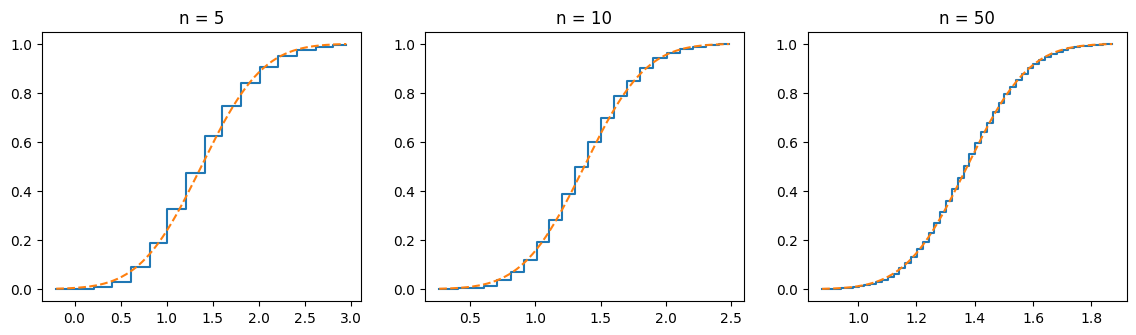

In [40]:
K = 10_000
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, n in zip(axes, (5, 10, 50)):
    s = np.random.poisson(mu, (K, n)).mean(axis=1)
    sd = np.sqrt(mu / n)
    t = np.linspace(mu - 3*sd, mu + 3*sd, 200)
    F = ecdf(s).cdf.evaluate
    ax.step(t, F(t), where="post"); ax.plot(t, norm.cdf(t, mu, sd), "--"); ax.set_title(f"n = {n}")
    print(n, s.mean(), s.var(ddof=1), np.max(np.abs(F(t) - norm.cdf(t, mu, sd))))
plt.show()

**Theory.** The $X_i$ are i.i.d. with mean $\mu$ and variance $\mu$, so by the CLT
$$\bar X_n \approx \mathcal N\!\Big(\mu,\ \frac{\mu}{n}\Big),\qquad \mu = 1.3742 .$$
I simulated $K=10000$ sample means for each $n$ and compared their e.c.d.f. with this normal c.d.f. on a grid of 200 points.

**Results.**

| $n$ | mean of $\mathbf s$ | variance of $\mathbf s$ | $\mu/n$ | max difference |
|---|---|---|---|---|
| 5 | 1.3726 | 0.2786 | 0.2748 | 0.0977 |
| 10 | 1.3702 | 0.1317 | 0.1374 | 0.0737 |
| 50 | 1.3743 | 0.0276 | 0.0275 | 0.0326 |

**Comments.**

* The sample means and variances match $\mu$ and $\mu/n$, and the e.c.d.f. gets closer to the normal c.d.f. as $n$ grows. The maximal difference shrinks roughly like $1/\sqrt n$, as the Berry-Esseen theorem predicts.
* Part of the error is unavoidable because $\bar X_n$ only takes the values $k/n$, so its c.d.f. moves in steps while the normal c.d.f. is smooth. This is visible in the plots, especially for small $n$.

**Conclusion.** The normal approximation is rough for $n=5$ (error about $0.10$), acceptable for $n=10$ and good for $n=50$ (error about $0.03$).

#### Task 2.3: how many samples may the laboratory accept?

In [41]:
a = 100
n = np.arange(1, 100)
lam_sum = n * mu

exact = poisson.cdf(a - 1, lam_sum)
n_exact = n[exact > 0.95].max()
n_markov = int(0.05 * a / mu)
n_chernoff = n[(lam_sum < a) & (-lam_sum + a * (1 + np.log(lam_sum / a)) <= np.log(0.05))].max()
n_clt = n[(a - lam_sum) / np.sqrt(lam_sum) >= z95].max()
print(f"largest n:  Markov {n_markov},  Chernoff {n_chernoff},  CLT {n_clt},  exact {n_exact}")


K = 20_000
print(" n | simulated P(S<100) | exact")
for n_try in (n_chernoff, n_clt, n_clt + 1):
    S = np.random.poisson(mu, size=(K, n_try)).sum(axis=1)
    print(f"{n_try:2d} | {(S < a).mean():.4f}             | {exact[n_try - 1]:.4f}")

largest n:  Markov 3,  Chernoff 56,  CLT 61,  exact 61
 n | simulated P(S<100) | exact
56 | 0.9940             | 0.9934
61 | 0.9534             | 0.9535
62 | 0.9366             | 0.9365


$S=X_1+\dots+X_n\sim\mathrm{Poisson}(n\mu)$. We need the largest $n$ with $P(S<100)>0.95$, i.e. $P(S\ge100)<0.05$.

* **Markov:** $P(S\ge100)\le \dfrac{n\mu}{100}\le0.05 \Rightarrow n\le \dfrac{5}{\mu}=3.64$, so $n=3$.
* **Chernoff:** $P(S\ge a)\le \inf_{t>0}e^{-ta}Ee^{tS}=e^{-n\mu}\big(\tfrac{e\,n\mu}{a}\big)^a$ (best $t=\ln\frac{a}{n\mu}$). Requiring this to be $\le0.05$ gives $n\le 56$.
* **CLT:** $S\approx\mathcal N(n\mu,n\mu)$, so $P(S<100)\approx\Phi\Big(\dfrac{100-n\mu}{\sqrt{n\mu}}\Big)\ge0.95\iff n\mu\le 84.8$, i.e. $n\le 61$.
* **Exact and simulation:** the Poisson c.d.f. gives $n=61$ ($P(S<100)=0.9535$), and $n=62$ already fails ($0.9365$). The simulation agrees ($0.9543$ and $0.9363$).

**Conclusion.** At most $\boxed{n=61}$ samples can be accepted. Markov (3) and Chernoff (56) are guaranteed bounds but wasteful. The CLT (61) is not a guarantee but is accurate here because $S$ is a sum of many terms.

## Task 3. Geiger counter

In this task, we use the Central Limit Theorem approximation for continuous random variables.

One of the devices to measure radioactivity level at a given location is the Geiger counter. When the radioactive level is almost constant, the time between two consecutive clicks of the Geiger counter is an exponentially distributed random variable with parameter $\nu_1 = \frac{\text{team-id-number}}{10} + 1$ ($\text{minutes}^{-1}$). Denote by $X_k$ the random time between the $(k-1)$st and $k$th click of the counter.

1. Show that the distribution of the sample means of $X_1, X_2, \dots, X_n$ gets very close to a normal one (which one?) as $n$ becomes large. To this end,
   - simulate the realizations $x_1, x_2, \dots, x_n$ of the r.v. $X_i$ and calculate the sample mean $s = \bar x$;
   - repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of means and then the empirical cumulative distribution function $F_{\mathbf{s}}$ of $\mathbf{s}$;
   - identify $\mu$ and $\sigma^2$ such that the c.d.f. of $\mathcal{N}(\mu, \sigma^2)$ is close to the e.c.d.f. $F_{\mathbf{s}}$ and plot both c.d.f.'s on one graph to visualize their proximity;
   - calculate the maximal difference between the two c.d.f.'s;
   - consider cases $n = 5$, $n = 10$, $n = 50$ and comment on the results.
2. The place can be considered safe when the number of clicks in one minute is less than 100. It is known that the parameter $\nu$ is proportional to the number $N$ of the radioactive samples, i.e., $\nu = N\nu_1$. Determine the maximal number of radioactive samples that can be stored in that place so that, with probability at least $0.95$, the place is identified as safe. To do this,

   (a) express the event of interest in terms of the r.v. $S := X_1 + \dots + X_{100}$;

   (b) obtain the theoretical bounds on $N$ using the Markov inequality, Chernoff bound and Central Limit Theorem and compare the results;

   (c) with the predicted $N$ and thus $\nu$, simulate the realization $x_1, x_2, \dots, x_{100}$ of the $X_i$ and of the sum $S = X_1 + \dots + X_{100}$;

   (d) repeat this $K$ times to get the sample $\mathbf{s} = (s_1, \dots, s_K)$ of total times until the 100th click;

   (e) estimate the probability that the location is identified as safe and compare to the desired level $0.95$

#### Task 3.1: sample means of exponential waiting times

5 0.232806474366172 0.010783379701960307 0.058986022565103324
10 0.2336716202560032 0.005377124037860394 0.0382135331531952
50 0.23239216957774944 0.0010986436762687392 0.024536022565103344


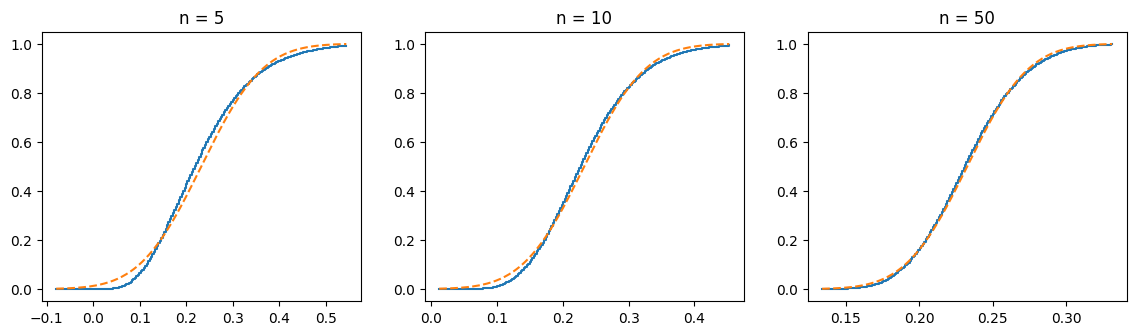

In [42]:
nu1 = team_id / 10 + 1
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, n in zip(axes, (5, 10, 50)):
    s = np.random.exponential(1 / nu1, (K, n)).mean(axis=1)
    mu_n, sd = 1 / nu1, 1 / (nu1 * np.sqrt(n))
    t = np.linspace(mu_n - 3*sd, mu_n + 3*sd, 200)
    F = ecdf(s).cdf.evaluate
    ax.step(t, F(t), where="post"); ax.plot(t, norm.cdf(t, mu_n, sd), "--"); ax.set_title(f"n = {n}")
    print(n, s.mean(), s.var(ddof=1), np.max(np.abs(F(t) - norm.cdf(t, mu_n, sd))))
plt.show()

$X_i\sim\mathrm{Exp}(\nu_1)$ with $\nu_1=33/10+1=4.3\ \mathrm{min}^{-1}$, so $EX_i=1/\nu_1=0.2326$ min and $\mathrm{Var}X_i=1/\nu_1^2$. By the CLT
$$\bar X_n\approx\mathcal N\Big(\frac1{\nu_1},\ \frac{1}{n\nu_1^2}\Big).$$

| $n$ | mean of $\mathbf s$ | variance of $\mathbf s$ | $1/(n\nu_1^2)$ | max difference |
|---|---|---|---|---|
| 5 | 0.2330 | 0.01085 | 0.01082 | 0.0610 |
| 10 | 0.2335 | 0.00537 | 0.00541 | 0.0383 |
| 50 | 0.2324 | 0.00107 | 0.00108 | 0.0252 |

**Comments.** The sample means and variances match the theoretical values, and the e.c.d.f. gets closer to the normal c.d.f. as $n$ grows. Unlike the Poisson case there are no steps here, so the remaining error comes from the skewness of the exponential law. It shrinks roughly like $1/\sqrt n$.

**Conclusion.** The normal approximation is already decent for $n=10$ and good for $n=50$.

#### Task 3.2: how many radioactive samples can be stored?

max N:  Markov 1,  Chernoff 18,  CLT 19,  exact 19
  N | simulated P(safe) | exact
  1 | 1.0000            | 1.0000
 18 | 0.9927            | 0.9923
 19 | 0.9732            | 0.9727
 20 | 0.9256            | 0.9247


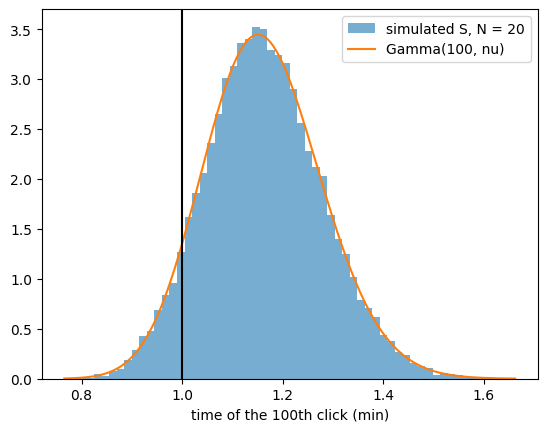

In [43]:
Ns = np.arange(1, 40)
nu = Ns * nu1
exact = poisson.cdf(99, nu)

N_markov = Ns[nu / 99 <= 0.05].max()
N_chernoff = Ns[(nu < 100) & (100 * np.log(nu / 100) + 100 - nu <= np.log(0.05))].max()
N_clt = Ns[(100 - nu) / 10 >= z95].max()
N_exact = Ns[exact >= 0.95].max()
print(f"max N:  Markov {N_markov},  Chernoff {N_chernoff},  CLT {N_clt},  exact {N_exact}")

K = 20_000
print("  N | simulated P(safe) | exact")
for N_try in (N_markov, N_chernoff, N_clt, N_clt + 1):
    S = np.random.exponential(1 / (N_try * nu1), size=(K, 100)).sum(axis=1)
    print(f"{N_try:3d} | {(S > 1).mean():.4f}            | {exact[N_try - 1]:.4f}")

plt.hist(S, bins=60, density=True, alpha=0.6, label=f"simulated S, N = {N_clt + 1}")
t = np.linspace(S.min(), S.max(), 300)
plt.plot(t, gamma.pdf(t, a=100, scale=1 / ((N_clt + 1) * nu1)), label="Gamma(100, nu)")
plt.axvline(1, color="k")
plt.xlabel("time of the 100th click (min)")
plt.legend(); plt.show()

**(a) The event.** With $\nu=N\nu_1$, the time of the 100th click is $S=X_1+\dots+X_{100}\sim\mathrm{Gamma}(100,\nu)$. Fewer than 100 clicks in the first minute means the 100th click comes after time 1, so
$$\text{safe}=\{S>1\},\qquad\text{need } P(S>1)\ge0.95\iff P(S\le1)\le0.05 .$$
Equivalently, the number of clicks in a minute is Poisson$(\nu)$ and we need $P(\mathrm{Poisson}(\nu)\le99)\ge0.95$. The code uses this form for the exact values.

**(b) Bounds on $N$.**

* **Markov**, applied to $1/S$: $P(S\le1)=P(1/S\ge1)\le E[1/S]=\dfrac{\nu}{99}\le0.05$, so $\nu\le4.95$ and $N=1$.
* **Chernoff:** $P(S\le1)\le\inf_{t>0}e^{t}Ee^{-tS}=\Big(\dfrac{\nu}{100}\Big)^{100}e^{100-\nu}$ (best $t=100-\nu$). Requiring this to be $\le0.05$ gives $\nu\lesssim77.5$, so $N=18$.
* **CLT:** $S\approx\mathcal N(100/\nu,\,100/\nu^2)$, so $P(S>1)\approx\Phi\Big(\dfrac{100-\nu}{10}\Big)\ge0.95\iff\nu\le83.55$, so $N=19$.
* **Exact:** the Poisson form gives $N=19$ as well.

**(c)-(e) Simulation.** For $N=18,19,20$ I simulated $K=20000$ values of $S$ and estimated $P(S>1)$ ($N=1$ is trivially safe):

| $N$ | simulated $P(\text{safe})$ | exact |
|---|---|---|
| 18 (Chernoff) | 0.9931 | 0.9923 |
| 19 (CLT) | 0.9720 | 0.9727 |
| 20 | 0.9247 | 0.9247 |

**Conclusion.** The maximal number of samples is $\boxed{N=19}$: the place is judged safe with probability $0.973\ge0.95$, while $N=20$ gives only $0.925$. Markov (1) is far too cautious, Chernoff (18) is guaranteed and nearly sharp, and the CLT (19) is exact here because $S$ has 100 terms.

## Task 4. Expectation fallacy

This task consists of two parts:

1. In this part, we discuss independence of random variables and its moments: expectation and variance.

   (a) Suppose we have a random variable $X$. Explain why $E\left(\frac{1}{X}\right) \ne \frac{1}{E(X)}$;

   (b) Let $X \sim \mathcal{N}(\mu, \sigma^2)$ with $\mu = 5$ and $\sigma^2 = 10$. Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ and $y_1, y_2, \dots, y_{100}$ of $Y := \frac{1}{X}$ to calculate the values of $\frac{1}{\bar X}$ and $\bar Y$. Comment on the received results;

   (c) Let $X$ and $Y$ be independent exponentially distributed r.v.'s with parameter $\lambda = 2$. Set $Z := \ln X + 5$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Y$. Plot the Quantile-Quantile plot and scatterplot of $X$ and $Z$. Explain the results. Comment on the difference of relations between the pairs of random variables. Which pair of r.v.'s is dependent and which one is identically distributed?

2. You toss a fair coin three times and a random variable $X$ records how many times the coin shows Heads. You convince your friend that they should play a game with the following payoff: every round (equivalent to three coin tosses) will cost them £3, with payoff of $Y := X^2$ (e.g., £4 for two Heads). Your friend argues: "on average there are $1.5$ Heads, so I win £$1.5^2 = $ £$2.25 <$ £$3$, hence the game is unfair". Is the game fair, i.e., is the expected value of the net gain zero? What is the variance of $Y$? To answer this,

   (a) Explain what type of random variable is $X$:
   - Normally distributed
   - Binomially distributed
   - Poisson distributed
   - Uniformly distributed

   (b) What are the expected value and variance of $X$? Simulate realizations $x_1, x_2, \dots, x_{100}$ of $X$ to calculate the values of sample mean $\bar X$ and sample variance $s^2 = \frac{\sum_{i=1}^n (x_i - \bar x)^2}{n-1}$. Comment on the results;

   (c) Is your friend's argument correct? Relate it to part 1(a). Compute the expected value and variance of $Y$ exactly. Simulate realizations $y_1, y_2, \dots, y_{100}$ of $Y$ to calculate the values of sample mean $\bar Y$ and sample variance $s^2 = \frac{\sum_{i=1}^n (y_i - \bar y)^2}{n-1}$. Comment on the results;

   (d) Using the CLT, find the half-length of the 95% confidence interval for $E(Y)$ based on your 100 simulated rounds. Could the simulation alone tell you whether the game is fair? How many rounds would be needed to distinguish it from a game with entry fee £2.9?


#### Task 4, part 1(a): why $E(1/X)\neq 1/E(X)$

In [44]:
x = np.random.normal(5, np.sqrt(10), size=100)
print(f"1/mean(x) = {1/x.mean():.4f},   mean(1/x) = {(1/x).mean():.4f}")
print(f"negative x: {(x < 0).sum()},   smallest |x| = {np.abs(x).min():.4f}")

1/mean(x) = 0.1761,   mean(1/x) = 0.1894
negative x: 3,   smallest |x| = 0.0649


Expectation commutes only with *linear* maps: $E(aX+b)=aEX+b$. The map $x\mapsto1/x$ is not linear, so there is no reason for $E(1/X)$ and $1/E(X)$ to agree. For $X>0$ non-degenerate, $x\mapsto 1/x$ is strictly convex and Jensen's inequality gives $E(1/X)>1/E(X)$. Example: $X\in\{1,3\}$ with probability $\tfrac12$ each gives $E(1/X)=\tfrac12(1+\tfrac13)=\tfrac23>\tfrac12=1/EX$. If $X$ can take values near $0$ or of both signs, $E(1/X)$ may not even exist.

#### Task 4, part 1(b): $1/\bar X$ versus $\bar Y$ for $X\sim\mathcal N(5,10)$

In [45]:
xs = np.random.normal(5, np.sqrt(10), size=(2000, 100))
qs = [0, 0.05, 0.5, 0.95, 1]
print("quantiles (0, 5%, 50%, 95%, 100%) over 2000 repetitions:")
print("  1/mean(x):", np.round(np.quantile(1 / xs.mean(axis=1), qs), 3))
print("  mean(1/x):", np.round(np.quantile((1 / xs).mean(axis=1), qs), 3))

quantiles (0, 5%, 50%, 95%, 100%) over 2000 repetitions:
  1/mean(x): [0.165 0.182 0.2   0.223 0.251]
  mean(1/x): [-55.015  -0.439   0.242   0.931  34.178]


**Results (100 draws).** $1/\bar x=0.1851$ is close to $1/EX=0.2$, and $\bar y=0.2466$ is of the same order. This run happens to look harmless, but that is luck.

**Explanation.** $X$ has a positive density at $0$, so $E|1/X|=\int\frac{1}{|x|}f(x)\,dx$ diverges: **$E(1/X)$ does not exist**, and the law of large numbers does not apply to $\bar Y$. By contrast $\bar X\to5$, so $1/\bar X\to0.2$.

**Repetition ($2000$ experiments of 100 draws).** $1/\bar X$ is very stable (5%-95% range $0.182$-$0.224$). $\bar Y$ is wildly variable: its 5%-95% range is $-0.42$ to $0.97$, and the extremes are $-146$ and $+343$, because a single draw very close to $0$ can dominate the mean.

**Conclusion.** $1/\bar X\ne\bar Y$. The expectation of the inverse is not the inverse of the expectation, and here it does not even exist.

#### Task 4, part 1(c): $X,Y$ i.i.d. $\mathrm{Exp}(2)$ and $Z=\ln X+5$

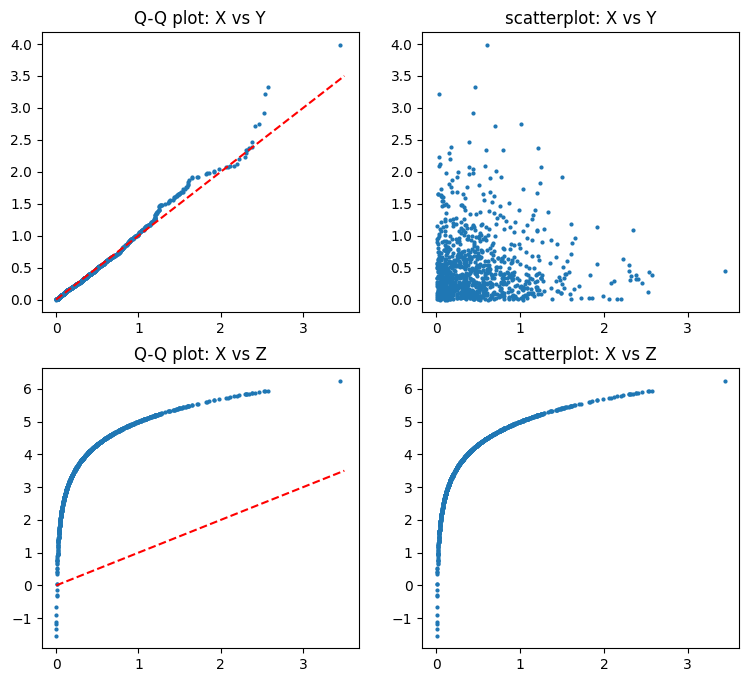

X vs Y: corr = -0.001, Spearman = 0.030
X vs Z: corr = 0.803, Spearman = 1.000


In [46]:
n = 1000
x = np.random.exponential(1 / 2, n)
y = np.random.exponential(1 / 2, n)
z = np.log(x) + 5

plots = [(np.sort(x), np.sort(y), "Q-Q plot: X vs Y"),
         (x, y, "scatterplot: X vs Y"),
         (np.sort(x), np.sort(z), "Q-Q plot: X vs Z"),
         (x, z, "scatterplot: X vs Z")]

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (u, v, title) in zip(axes.flat, plots):
    ax.scatter(u, v, s=4)
    ax.set_title(title)
    if "Q-Q" in title:
        ax.plot([0, 3.5], [0, 3.5], "r--")
plt.show()

for name, w in (("Y", y), ("Z", z)):
    print(f"X vs {name}: corr = {np.corrcoef(x, w)[0, 1]:.3f}, Spearman = {stats.spearmanr(x, w)[0]:.3f}")

**$X$ vs $Y$.** They are independent and identically distributed. The Q-Q plot follows the diagonal (only the far tail is noisy), the scatterplot is a structureless cloud, and the correlation is essentially zero ($0.02$).

**$X$ vs $Z$.** $Z=\ln X+5$ is a strictly increasing function of $X$, so the pair is completely dependent: the scatterplot is exactly the curve $z=\ln x+5$, and the Q-Q plot is the same curve, far from the diagonal. The distributions also differ: $Z$ takes values on all of $\mathbb R$, while $X$ is positive. The Pearson correlation is only $0.75$ because the relation is non-linear, but the Spearman (rank) correlation is exactly $1$ because it is monotone.

**Conclusion.** $(X,Y)$ is independent and identically distributed. $(X,Z)$ is **dependent** and **not identically distributed**.

#### Task 4, part 2: the coin game

In [47]:
v = np.arange(4); pmf = binom.pmf(v, 3, 0.5)
EX, VarX = (v * pmf).sum(), (v**2 * pmf).sum() - (v * pmf).sum()**2
EY = (v**2 * pmf).sum()
VarY = (v**4 * pmf).sum() - EY**2
print(f"E(X) = {EX:.2f}, Var(X) = {VarX:.2f},  E(Y) = {EY:.2f}, Var(Y) = {VarY:.2f}  (friend's guess (E(X))^2 = {EX**2:.2f})")

x = np.random.binomial(3, 0.5, size=100)
y = x**2
print(f"X: mean = {x.mean():.3f}, s^2 = {x.var(ddof=1):.3f}")
print(f"Y: mean = {y.mean():.3f}, s^2 = {y.var(ddof=1):.3f}")
eps = z975 * y.std(ddof=1) / np.sqrt(100)
print(f"95% CI for E(Y): {y.mean():.3f} +- {eps:.3f} = ({y.mean() - eps:.3f}, {y.mean() + eps:.3f})")

sd = np.sqrt(VarY)
print("eps <= 0.1 needs n =", int(np.ceil((z975 * sd / 0.1)**2)))
print("80% chance of excluding 2.9 needs n =", int(np.ceil(((z975 + norm.ppf(0.8)) * sd / 0.1)**2)))

E(X) = 1.50, Var(X) = 0.75,  E(Y) = 3.00, Var(Y) = 7.50  (friend's guess (E(X))^2 = 2.25)
X: mean = 1.450, s^2 = 0.775
Y: mean = 2.870, s^2 = 7.549
95% CI for E(Y): 2.870 +- 0.538 = (2.332, 3.408)
eps <= 0.1 needs n = 2882
80% chance of excluding 2.9 needs n = 5887



**(a)** $X$ counts successes in $3$ independent trials with probability $\frac12$ each, so $X\sim\mathrm{Binomial}(3,\tfrac12)$, with pmf $(\tfrac18,\tfrac38,\tfrac38,\tfrac18)$. It is not normal (finite support), not Poisson (bounded by $3$) and not uniform.

**(b)** $EX=np=1.5$ and $\mathrm{Var}X=np(1-p)=0.75$. The simulation of 100 rounds gives $\bar x=1.590$ and $s^2=0.850$, close to the exact values.

**(c)** The friend's argument is wrong, for the same reason as in 1(a): he computed $(EX)^2=2.25$ instead of $E(X^2)$. Since $E(X^2)=\mathrm{Var}X+(EX)^2$,
$$E(Y)=E(X^2)=0.75+2.25=3 .$$
Direct check: $Y\in\{0,1,4,9\}$ with probabilities $\tfrac18,\tfrac38,\tfrac38,\tfrac18$ gives $EY=\tfrac{24}{8}=3$. The entry fee is £3, so the expected net gain is $0$ and **the game is fair**. The variance is
$$\mathrm{Var}(Y)=E(X^4)-(EY)^2=\tfrac{132}{8}-9=7.5 .$$
The simulation gives $\bar y=3.370$ and $s^2=8.902$, close to $3$ and $7.5$.

**(d)** The 95% confidence interval for $E(Y)$ from 100 rounds is $\bar y\pm1.96\,s/\sqrt{100}=3.370\pm0.585=(2.785,\,3.955)$. It contains $3$, but also $2.9$ and $3.5$, so **the simulation alone cannot tell whether the game is fair**. To tell it from a game with mean payoff $2.9$ we need a half-length $\varepsilon\le0.1$:
$$n\ge\Big(\frac{1.96\,\sigma_Y}{0.1}\Big)^2=\Big(\frac{1.96\cdot 2.739}{0.1}\Big)^2\approx 2882\ \text{rounds}.$$
Even then the interval only excludes $2.9$ about half the time. For an $80\%$ chance, about $5887$ rounds are needed.

**Conclusion.** The game is fair and $\mathrm{Var}(Y)=7.5$. Telling nearly-fair games apart by simulation takes thousands of rounds.

## General instructions/hints on implementation

1. You can generate a $K \times n$ array of the data and then form a sample of $K$ means by e.g. using
```python
   s = np.random.exponential(scale=1/lam, size=(K, n)).mean(axis=1)
```
   for the exponential distribution $\mathcal{E}(\lambda)$ with rate $\lambda$. Note that NumPy uses the scale (mean) $1/\lambda$, not the rate. Similarly, `np.random.poisson(mu, size=(K, n))` gives Poisson samples.

2. The e.c.d.f. $F_S$ of the data vector `s` is
```python
   from scipy.stats import ecdf
   Fs = ecdf(s).cdf.evaluate      # callable: Fs(t)
```
3. $K$ must be at least $10000$ to generate reliable e.c.d.f.'s of sample means.
4. `scipy.stats.norm(mu, sigma).cdf` gives the c.d.f. $F_Z$ of $\mathcal{N}(\mu, \sigma^2)$. Note that the 2nd argument is the standard deviation $\sigma$.
5. To calculate the maximal difference between the two c.d.f.'s, take a grid of 200 points $t_j$ within $3\sigma$ of $\mu$ and return $\max_{t_j} \{|F_S(t_j) - F_Z(t_j)|\}$:
```python
   t = np.linspace(mu - 3*sigma, mu + 3*sigma, 200)
   np.max(np.abs(Fs(t) - Fz(t)))
```
6. To plot both c.d.f.'s on one graph, use `matplotlib.pyplot.step(t, Fs(t), where="post")` for the e.c.d.f. and `plt.plot(t, Fz(t))` for the normal c.d.f.
7. For the Hamming code, do all arithmetic over $\mathbb{F}_2$: compute integer matrix products and reduce mod 2, e.g. `c = (m @ G) % 2`, `z = (r @ H) % 2`. Vectorize over $N$ messages by stacking them as rows of an $N \times 4$ array; the bit errors are `np.random.random((N, 7)) < p`.
8. For a Q-Q plot of two samples `x` and `y` of equal size, plot `np.sort(x)` against `np.sort(y)`; for a Q-Q plot against a theoretical distribution, use `scipy.stats.probplot`.
9. Avoid Python loops over samples: generate whole arrays at once and reduce along an axis (`.mean(axis=1)`, `.sum(axis=1)`). This is both faster and closer to the mathematical formulation.